# Tutorial 3: Iterative Plate Solving

To start, we will need to load in the results from Tutorial 2. We will need the CCD pixel coordinates (x,y) for each star we have identified in our image. And the projected standard coordinates of each star taken from the USNO-B catalog.

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import pandas as pd
import ta_funcs_asteroid as ta

#Read the cleaned image (We use only a corner of one image for demonstration)
img = fits.open('Data/26Proserpina/Cleaned/cleaned_20120119.fits')[0].data

ITERATION_NUM = 0

if ITERATION_NUM == 0:
    #Read in the star data from the cross matching
    star_data =  pd.read_csv('Data/26Proserpina/Crossmatched/20120119_usno_approx.csv')
elif ITERATION_NUM == 1:
    # #Read in the star data from the cross matching
    star_data =  pd.read_csv('Data/26Proserpina/Crossmatched/20120119_usno_0.csv')

print(f"We have cross matched {len(star_data)} Stars! Here are the first few.")

star_data.head()

We have cross matched 741 Stars! Here are the first few.


,USNO-B1.0,RAJ2000,DEJ2000,USNO_approx_x,USNO_approx_y,Centroid_x,Centroid_y,Separation,R2mag,pmRA,pmDE
0,1169-0081221,81.360670,26.901775,1997.762257,763.845624,1983.492930,761.427404,14.472785,11.90,0.0,0.0
1,1168-0078077,81.183156,26.862417,1465.501090,640.294686,1455.751944,641.055580,9.778793,14.24,0.0,-6.0
2,1169-0080485,81.079787,26.972825,1163.017918,1015.154336,1157.589257,1013.046092,5.823663,10.14,0.0,-14.0
3,1168-0078390,81.338495,26.813228,1927.084121,468.311614,1935.199828,477.591937,12.328386,15.63,0.0,0.0
4,1168-0077993,81.142589,26.845937,1343.399721,587.098474,1334.761897,588.842427,8.812115,14.09,0.0,-12.0


In [16]:
#Now we can extract each column to work with. 
usno_ra = star_data["RAJ2000"]
usno_dec = star_data["DEJ2000"]
ccd_x = star_data["Centroid_x"]
ccd_y = star_data["Centroid_y"]
usno_x_approx = star_data["USNO_approx_x"]
usno_y_approx = star_data["USNO_approx_y"]
usno_X = np.empty_like(usno_x_approx)
usno_Y = np.empty_like(usno_x_approx)

#We are also going to need to projects standard coordinates for each of the USNO stars. 
#This was part of the approximate transform step in last tutorial 

#From the data FITS header.
center_of_field = ['05 24 07.53', '+26 58 50.5']
alpha0, delta0 = ta.convert2deg(*center_of_field)

#For each star, Compute corresponding Standard Coordinates (Equation in Lab Manual)
for i in range(usno_ra.shape[0]):
    usno_X[i], usno_Y[i] = ta.get_XY(usno_ra[i], usno_dec[i], alpha0, delta0)

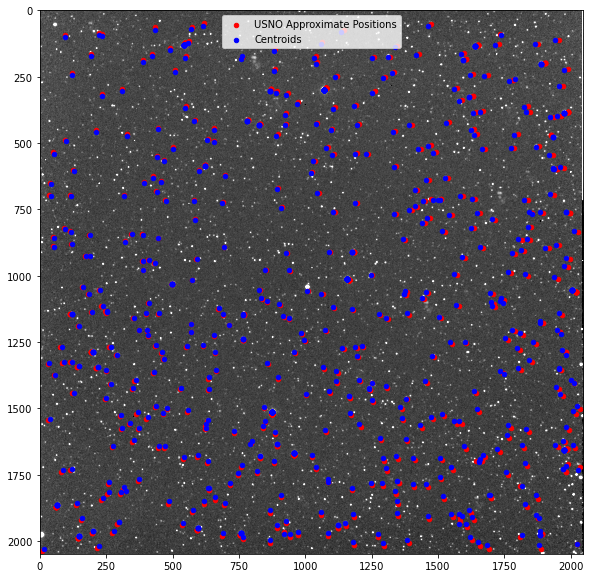

In [17]:
#Let's Plot the data to see were we are at
plt.figure(figsize=(10,10))
contrast = 1 #higher number will make more contrast
vmin, vmax = np.percentile(img,contrast),np.percentile(img,100-contrast)
plt.imshow(img, cmap='gray', vmin=vmin, vmax=vmax)
plt.scatter(usno_x_approx, usno_y_approx,s=20,color='red',label='USNO Approximate Positions')
plt.scatter(ccd_x, ccd_y,s=20,color='blue',label='Centroids')
plt.legend()

So we can see than the approximate transform gets us pretty close, but there is still a spatially varying descrepancy between the detected and transformed stars. 

In this tutorial, I will show you how to better model this transformation.

# Background 

Let's start with a review from last week, we can start by modelling the transformation our telescope is doing as a very basic rescalng and translation of the sky plane in standard coordinates (X, Y) to our CCD plane (x,y)

$$
x = \left(\frac{f}{p}\right)X + x_0\\
y = \left(\frac{f}{p}\right)Y + y_0
$$

Since our projection assumes a unit radius for the celestial sphere, the focal length of our camera, f, is the proportionality constant between our similar triangles. We then just divide by the pixel size, p, to express our values in terms of number of pixels, and add a translation to account for the fact that the center of our CCD is not at the origin. I.E. x0 and y0 are pointing offsets in pixels.  

Take a look at this image to visualize the trigonometry of the process to get from X,Y to x,y
![title](../FOV-fig-3-1024x483.png)

You can also add in a rotation offset (theta) between the planes as an additional free parameter, but the idea is still the same.

$$
x = \left(\frac{f}{p}\right)\left(X\cos(\theta) - Y\sin(\theta)\right)+ x_0\\
y = \left(\frac{f}{p}\right)\left(X\sin(\theta) + Y\cos(\theta) \right) + y_0
$$

So far, we have introduced 3 degrees of freedom (rotation + 2 translation). Taking this idea further, we can abstract our model to a general Affine Transformation between two planes. Mathmatically, an Affine transformation is a linear transformation and translation, and have the following form:

$$
\begin{bmatrix} \mathbf{y} \\ 1 \end{bmatrix}
= \left[ \begin{array}{ccc|c} & A & & \mathbf{b} \\ 0 & \cdots & 0 & 1 \end{array} \right]
\begin{bmatrix} \mathbf{x} \\ 1 \end{bmatrix}
$$

or in our case:

$$\vec{x}^{\,} = \mathbf{T}\vec{X}^{\,}$$

$$T = 
\begin{pmatrix}
a_{1,1}\left(\frac{f}{p}\right) & a_{1,2}\left(\frac{f}{p}\right) & \Delta x \\
a_{2,1}\left(\frac{f}{p}\right) & a_{2,2}\left(\frac{f}{p}\right) & \Delta y\\
0 & 0 & 1 
\end{pmatrix}
$$

Now we have introduced 4 unknowns, $a_{i,j}$, which we refer to as the "plate constants". And the act of "plate solving" the process of constraining these unknowns.

Once you get your 6 unknowns, you have effectively solve the system. But there is still more you can learn.
When dealing with Affine Transformations, we can break bowdn the unknowns into a set of more informative 'basis' operations. Namely, we have 2 magnification (x and y), 2 sheer (horizontal and vertical), 1 rotation, 2 translation  (x and y) for 7 in total. Note that the are not independent, the determinent provides an additional constraint to make the solution unique!

![title](../Selection_053.png)

Before we decompose our solution into this basis, we can first get our plate constants!

# Solving for the Plate Constants

We will be using a Least Squares solver. We can start by reading the documentation for Numpy's Least Squares Solver: https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html

The documentation says that we need our problem in the form: $$\mathbf{A}x = b$$ where we will be solving for the **vector/matrix x**. x can be a vector or a matrix, the math does not change. Be careful, the variable names get very confusing here. In our context, we have already set up the equation: 

$$ \mathbf{T}\vec{X}^{\,} = \vec{x}^{\,} $$

but we are trying to solve for the parameters inside of $\mathbf{T}$. So, when we use the numpy function the $x$ they refer to is our T. It's confusing!!! Take a second to think about this fully.

We need to reframe the problem. Let's image the transformation we are solving is to take a single USNO standard coordinate to a single CCD star. Lets rename the USNO star position as a 1x3 vector $\vec{a}^{\,} = [a_1, a_2, 1]$, and our resulting CCD star centroid as a 3x1 vector $\vec{b}^{\,} = [b_1, b_2]$. We can now write our affine transformation for a single star position as:

$$\vec{a}^{\,}\mathbf{T} = \vec{b}^{\,}$$

where T is a 3x2 transformation matrix, as expected. Now, we can increase the number of data points we have to constrain the problem very easily by expanding the vectors $\vec{a}^{\,}$ & $\vec{b}^{\,}$ into matrices $\mathbf{A}$ & $\mathbf{B}$ as follows:

$$\mathbf{A}_i = [a_{1,i}, a_{2,i}, 1]$$
$$\mathbf{B}_i = [b_{1,i}, b_{2,i}]$$

where the index $i$ indicates the ith observation, and equivalently, the ith row of the matrix. 

In [18]:
T, usno_x, usno_y = ta.get_T(ccd_x, ccd_y, usno_X, usno_Y)
np.save(f"T_{ITERATION_NUM}", T)

/home/jacob/AST325_github/AsteroidProperMotion/2024/ta_funcs_asteroid.py:827: FutureWarning: `rcond` parameter will change to the default of machine precision times ``max(M, N)`` where M and N are the input matrix dimensions.
To use the future default and silence this warning we advise to pass `rcond=None`, to keep using the old, explicitly pass `rcond=-1`.
  T = np.linalg.lstsq(A, B)[0]


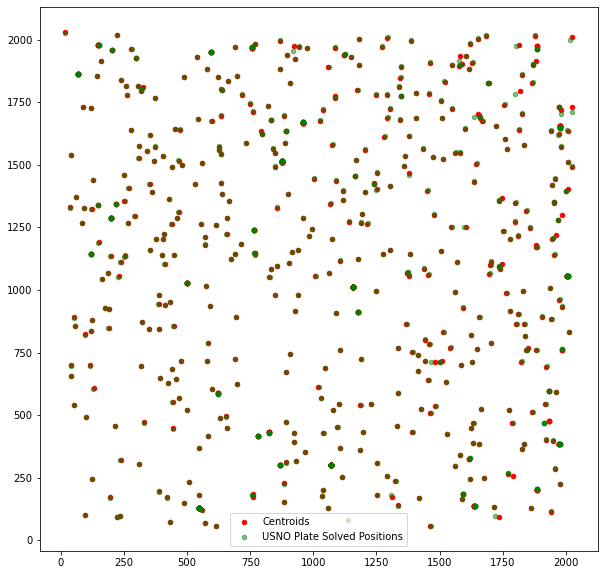

741 741


In [19]:
#Let's Plot the data to see were we are at
plt.figure(figsize=(10,10))
contrast = 1 #higher number will make more contrast
vmin, vmax = np.percentile(img,contrast),np.percentile(img,100-contrast)
# plt.imshow(img, cmap='gray', vmin=vmin, vmax=vmax)
# plt.scatter(usno_x_approx, usno_y_approx,s=20,color='red',label='USNO Approximate Positions', alpha=0.5)
plt.scatter(ccd_x, ccd_y,s=20,color='red',label='Centroids', alpha=1)
plt.scatter(usno_x, usno_y,s=20,color='green',label='USNO Plate Solved Positions', alpha=0.5)
plt.legend()
plt.show()

print(len(ccd_x), len(usno_x))

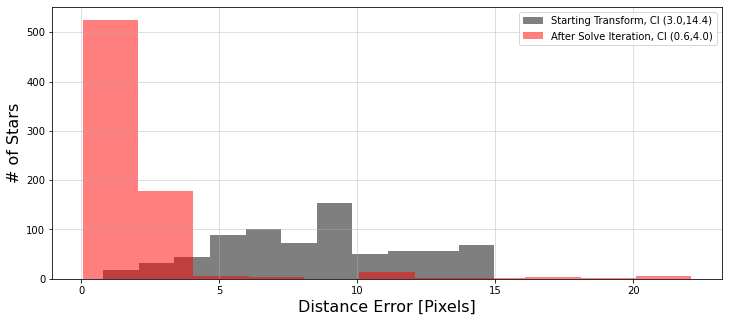

In [20]:
# For each star we have, calculate the distance between it and stars in the USNO catalog to find the closest one. 
def distance(x1,y1,x2,y2):
    return np.sqrt((x1-x2)**2+(y1-y2)**2)

min_dists_before = np.empty_like(usno_x)
min_dists_after = np.empty_like(usno_x)
for i in range(usno_x.size):
    min_dists_before[i] = np.min(distance(usno_x_approx[i], usno_y_approx[i], ccd_x, ccd_y))
    min_dists_after[i] = np.min(distance(usno_x[i], usno_y[i], ccd_x, ccd_y))

CI_b = (np.percentile(min_dists_before,5), 
      np.percentile(min_dists_before,95))
CI_a = (np.percentile(min_dists_after,5), 
      np.percentile(min_dists_after,95))


plt.figure(figsize=(12,5))
plt.hist(min_dists_before, 
         bins = "sturges", 
         color = 'k',
         alpha = 0.5, 
         label=f'Starting Transform, CI ({CI_b[0]:.1f},{CI_b[1]:.1f})')
plt.hist(min_dists_after, 
         bins = "sturges", 
         color = 'r',
         alpha = 0.5, 
         label =f'After Solve Iteration, CI ({CI_a[0]:.1f},{CI_a[1]:.1f})')
plt.grid(alpha=0.5)
plt.xlabel("Distance Error [Pixels]", size = 16)
plt.ylabel("# of Stars", size = 16)
plt.legend()
plt.show()


Now that we have an intial plate solution, we can go back to our original image and use more stars!

Originally, we relied on the "Approximate Transform" to get the stars to line up close enough, then we filtered stars using a distance threshold to determine exactly which star in the catalog corresponded to each centroid.

Now that we have a more accurate transformation, now we can go back to the top and use way more stars!

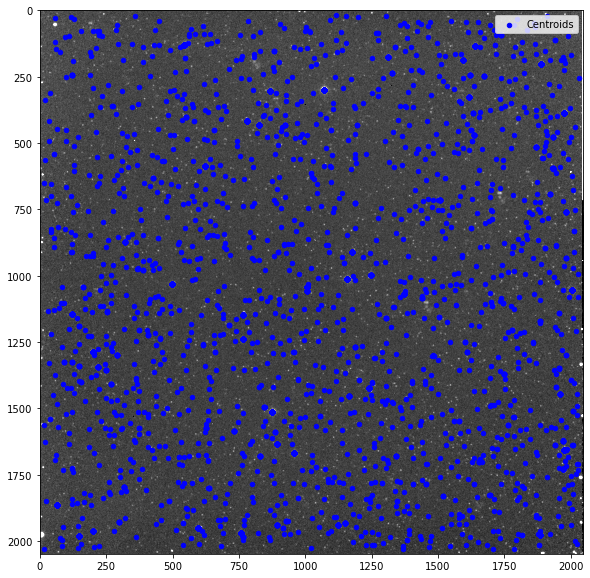

3377


In [21]:
#Here I have re-run my centroiding code to get more centroids
df = pd.read_csv('Data/26Proserpina/Centroids/20120119_fine.csv')

plt.figure(figsize=(10,10))
contrast = 1 #higher number will make more contrast
vmin, vmax = np.percentile(img,contrast),np.percentile(img,100-contrast)
plt.imshow(img, cmap='gray', vmin=vmin, vmax=vmax)
# plt.scatter(usno_x_approx, usno_y_approx,s=20,color='red',label='USNO Approximate Positions')
plt.scatter(df.x, df.y,s=20,color='blue',label='Centroids')
plt.legend()
plt.show()


print(len(df.x))